In [1]:
# source ~/load_modules_pitts_spack-26.1.sh
# module unload --no-auto py-typing-extensions py-pylint-gitlab -f
# module load py-pip
# OMP_NUM_THREADS=64 DISPLAY= PYTHONPATH=$PYTHONPATH:~/pitts_clean/examples/.python-packages/lib/python3.14/site-packages/:~/pitts_clean/build/src/ .python-packages/bin/jupyter notebook --no-browser --ip=0.0.0.0
import numpy as np
import os
import matplotlib.pyplot as plt
import pitts_py
from IPython import display
plt.rcParams['figure.figsize'] = [15, 10]
plt.rcParams['savefig.transparent'] = False
#plt.rcParams['agg.transparent'] = False

In [2]:
def dict_to_tensortrain(tt_dict):
    Xtt = pitts_py.TensorTrain_float(tt_dict['dimensions'])
    Xtt.setTTranks(tt_dict['ranks'])
    for i in range(len(Xtt.dimensions())):
        Xtt.setSubTensor(i, tt_dict['cores'][i])
    return Xtt

In [3]:
pitts_py.initialize()

PITTS: version v0.9.7-207-gc00bfa6
PITTS: MPI #procs: 1
PITTS: OpenMP #threads: 64
PITTS: SIMD implementation: avx512
PITTS: Eigen SIMD implementation: AVX512, FMA, AVX2, AVX, SSE, SSE2, SSE3, SSSE3, SSE4.1, SSE4.2
PITTS: cache sizes (L1/core, L2/core, L3/accessible) [byte]: (32768, 1048576, 92274688)
PITTS: preprocessor definitions: PITTS_DIRECT_MKL_GEMM


In [4]:
%%time
xtt_dict = np.load('Xtt_CERN_topTagging_unit_partially_ordered.npz', allow_pickle=True)
Xtt = dict_to_tensortrain(xtt_dict)
print(Xtt)

PITTS::TensorTrainfloat
        with dimensions = [1401, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1416]
             ranks      = [500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500]
CPU times: user 10.3 s, sys: 926 ms, total: 11.2 s
Wall time: 699 ms


In [6]:
for i in range(len(Xtt.dimensions())):
    subT = Xtt.getSubTensor(i)
    left = np.einsum('ijk,ijl->kl', subT, subT)
    right = np.einsum('ijk,ljk->il', subT, subT)
    print('Dim', i, 'left', np.linalg.norm(left - np.eye(*left.shape)) < 1.e-4, 'right', np.linalg.norm(right - np.eye(*right.shape)) < 1.e-4)

Dim 0 left True right False
Dim 1 left True right False
Dim 2 left True right False
Dim 3 left True right False
Dim 4 left True right False
Dim 5 left True right False
Dim 6 left True right False
Dim 7 left True right False
Dim 8 left False right False
Dim 9 left False right True
Dim 10 left False right True
Dim 11 left False right True
Dim 12 left False right True
Dim 13 left False right True
Dim 14 left False right True
Dim 15 left False right True
Dim 16 left False right True
Dim 17 left False right True


In [7]:
# extract all but first sub-tensor
dims = Xtt.dimensions()
r = Xtt.getSubTensor(0).shape[2]
I = np.eye(r, r, dtype=np.float32).reshape((1,r,r), order='C', copy=False)
dummy_subT = [I,] + [Xtt.getSubTensor(i) for i in range(1, len(dims))]
dummy_tt = pitts_py.TensorTrain_float([r,] + dims[1:])
dummy_tt.setTTranks([subT.shape[2] for subT in dummy_subT[:-1]])
for i, subT in enumerate(dummy_subT):
    dummy_tt.setSubTensor(i, subT)
print(dummy_tt)

PITTS::TensorTrainfloat
        with dimensions = [500, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1416]
             ranks      = [500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500]


In [87]:
%%time
# form U S^2 U^T (Gram matrix / cosine similarity) in compressed form
dims = Xtt.dimensions()
new_dims = list(reversed(dims[1:])) + dims[1:]
dummy_subT = [Xtt.getSubTensor(i) for i in range(1, len(dims))]
dummy_subT = [subT.T for subT in reversed(dummy_subT)] + dummy_subT
dummy_tt = pitts_py.TensorTrain_double(new_dims)
dummy_tt.setTTranks([subT.shape[2] for subT in dummy_subT[:-1]])
for i, subT in enumerate(dummy_subT):
    dummy_tt.setSubTensor(i, subT)
print(dummy_tt)
Xtt_cosineSimilarity = dummy_tt
nrm = pitts_py.normalize(Xtt_cosineSimilarity, rankTolerance=1.e-4, maxRank=150)
print(Xtt_cosineSimilarity)
print(nrm)

PITTS::TensorTraindouble
        with dimensions = [1416, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1416]
             ranks      = [500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500]
PITTS::TensorTraindouble
        with dimensions = [1416, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1416]
             ranks      = [150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 85, 43, 22, 11, 6, 4, 7, 13, 25, 49, 97, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150]
72418846.5014462
CPU times: user 2min 34s, sys: 5.49 s, total: 2min 40s
Wall time: 2.83 s


In [88]:
# Gaussian RBF kernel
def TT_cross_Gaussian(Xtt, nrm, sigma, tolerance=1.e-3, maxRank=1000):

    def kernel_inplace(values):
        values *= nrm
        values -= 1
        #print('max(1 - g):', np.max(-values))
        #print('max(g - 1):', np.max(values))
        values /= sigma**2
        np.exp(values, out=values)

    Ytt = pitts_py.TensorTrain_double(Xtt.dimensions())
    pitts_py.applyElementwise(kernel_inplace, Xtt, Ytt,
                              convergenceTolerance=tolerance, maxRank=maxRank, enrichmentRank=maxRank//20, errorRank=maxRank//7,
                              rankTolerance=0.1*tolerance, nMALS=1, nSweeps=1, controlSampleSize=10000, verbose=True, maxvolTolerance=0.001)
    return Ytt

In [103]:
%%time
Xtt_Gaussian = TT_cross_Gaussian(Xtt_cosineSimilarity, nrm, sigma=1, tolerance=1.e-3, maxRank=1000)
print(Xtt_Gaussian)

TT-cross sweep 0.5: change 1, error estimate 1.0185, sampled error 0, ranks: 200 200 200 200 200 200 200 200 200 200 191 128 90 70 59 49 31 53 62 74 98 141 191 199 200 200 200 200 200 200 199 200 200
TT-cross sweep 1: change 0.000449621, error estimate 0.0140365, sampled error 0.0013977, ranks: 164 169 180 192 194 195 195 195 190 168 140 79 44 25 14 8 5 8 14 26 50 97 150 157 195 195 195 195 194 178 171 178 196
PITTS::TensorTraindouble
        with dimensions = [1416, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1416]
             ranks      = [164, 169, 180, 192, 194, 195, 195, 195, 190, 168, 140, 79, 44, 25, 14, 8, 5, 8, 14, 26, 50, 97, 150, 157, 195, 195, 195, 195, 194, 178, 171, 178, 196]
CPU times: user 2min 27s, sys: 4.68 s, total: 2min 32s
Wall time: 5.18 s


In [104]:
%%time
pitts_py.internal.ensureLeftOrtho_range(Xtt_Gaussian, 0, 17)
pitts_py.internal.ensureRightOrtho_range(Xtt_Gaussian, 17, 33)

CPU times: user 6.67 s, sys: 263 ms, total: 6.93 s
Wall time: 110 ms


In [105]:
#for i in range(len(Xtt_Gaussian.dimensions())):
#    subT = Xtt_Gaussian.getSubTensor(i)
#    left = np.einsum('ijk,ijl->kl', subT, subT)
#    right = np.einsum('ijk,ljk->il', subT, subT)
#    print('Dim', i, 'left', np.linalg.norm(left - np.eye(*left.shape)) < 1.e-4, 'right', np.linalg.norm(right - np.eye(*right.shape)) < 1.e-4)

In [106]:
%%time
subT17 = Xtt_Gaussian.getSubTensor(17)
print('old shape', subT17.shape)
U, S, Vt = np.linalg.svd(subT17.reshape((subT17.shape[0], subT17.shape[1]*subT17.shape[2]), order='F'), full_matrices=False)
subT16 = Xtt_Gaussian.getSubTensor(16)
subT16 = np.einsum('ijk,kl->ijl', subT16, U)
subT17 = (np.diag(S) @ Vt).reshape((S.shape[0], subT17.shape[1], subT17.shape[2]), order='F')
print('new shape', subT17.shape)
Xtt_Gaussian.setSubTensor(16, subT16)
Xtt_Gaussian.setSubTensor(17, subT17)

old shape (5, 2, 8)
new shape (5, 2, 8)
CPU times: user 1.47 ms, sys: 20 μs, total: 1.49 ms
Wall time: 1.06 ms


In [107]:
S

array([7.45124026e+07, 3.62287168e+05, 8.82367971e+03, 5.26811033e+03,
       1.97739491e+03])

In [108]:
# need the row sums -> (partial) scalar product with a unit TT
def rowSum(Xtt):
    tmp = np.ones((1,))
    dims = Xtt.dimensions()
    for i in range(len(dims)//2):
        subT = Xtt.getSubTensor(len(dims)-i-1)
        tmp = subT.reshape((subT.shape[0]*subT.shape[1],subT.shape[2]), order='F') @ tmp
        tmp = tmp.reshape((subT.shape[0], subT.shape[1]), order='F')
        tmp = np.sum(tmp, axis=1)
    # sub-tensor left from the middle
    subT = Xtt.getSubTensor(len(dims)//2-1)
    last_subT = subT.reshape((subT.shape[0]*subT.shape[1], subT.shape[2]), order='F') @ tmp
    last_subT = last_subT.reshape((subT.shape[0], subT.shape[1], 1), order='F')
    tt = pitts_py.TensorTrain_double(dims[:len(dims)//2])
    new_subT = [Xtt.getSubTensor(i) for i in range(len(dims)//2-1)] + [last_subT,]
    tt.setTTranks([subT.shape[2] for subT in new_subT[:-1]])
    for i, subT in enumerate(new_subT):
        tt.setSubTensor(i, subT)
    return tt

In [109]:
%%time
d_tt = rowSum(Xtt_Gaussian)
print(d_tt)
d_nrm = pitts_py.normalize(d_tt, rankTolerance=0.001)
print(d_tt)
d_tt.setSubTensor(0, d_tt.getSubTensor(0)*d_nrm)

PITTS::TensorTraindouble
        with dimensions = [1416, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
             ranks      = [164, 169, 180, 192, 194, 195, 195, 195, 190, 168, 140, 79, 44, 25, 14, 8]
PITTS::TensorTraindouble
        with dimensions = [1416, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
             ranks      = [145, 143, 142, 141, 147, 150, 150, 148, 145, 123, 63, 32, 16, 8, 4, 2]
CPU times: user 9.99 s, sys: 433 ms, total: 10.4 s
Wall time: 219 ms


In [110]:
dims = Xtt_Gaussian.dimensions()
D_tt = pitts_py.TensorTrain_double(Xtt_Gaussian.dimensions())
D_subT = [d_tt.getSubTensor(i) for i in range(len(dims)//2)]
D_subT += [subT.T for subT in reversed(D_subT)]
D_tt.setTTranks([subT.shape[2] for subT in D_subT[:-1]])
for i, subT in enumerate(D_subT):
    D_tt.setSubTensor(i, subT)
print(D_tt)

PITTS::TensorTraindouble
        with dimensions = [1416, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1416]
             ranks      = [145, 143, 142, 141, 147, 150, 150, 148, 145, 123, 63, 32, 16, 8, 4, 2, 1, 2, 4, 8, 16, 32, 63, 123, 145, 148, 150, 150, 147, 141, 142, 143, 145]


In [111]:
Xtt_Gaussian_normalized = pitts_py.TensorTrain_double(Xtt_Gaussian.dimensions())
def scale_inplace(val1, val2):
    np.divide(val1, np.sqrt(val2), out=val1)

pitts_py.applyElementwise(scale_inplace, Xtt_Gaussian, D_tt, Xtt_Gaussian_normalized,
                          convergenceTolerance=1.e-3, maxRank=750, enrichmentRank=0//20, errorRank=100,
                          rankTolerance=1.e-4, nMALS=1, nSweeps=1, controlSampleSize=500, verbose=True, maxvolTolerance=0.001)
print(Xtt_Gaussian_normalized)

TT-cross sweep 0.5: change 1, error estimate 0, sampled error 0, ranks: 195 172 180 208 256 300 320 328 326 278 196 108 58 32 17 9 5 9 17 33 64 118 195 271 330 337 340 340 335 313 304 300 303
TT-cross sweep 1: change 0.0004724, error estimate 0, sampled error 0.00210613, ranks: 162 162 166 194 235 276 301 314 315 266 184 104 57 32 17 9 5 9 17 33 64 117 191 266 326 333 337 337 331 307 294 293 300
PITTS::TensorTraindouble
        with dimensions = [1416, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1416]
             ranks      = [162, 162, 166, 194, 235, 276, 301, 314, 315, 266, 184, 104, 57, 32, 17, 9, 5, 9, 17, 33, 64, 117, 191, 266, 326, 333, 337, 337, 331, 307, 294, 293, 300]


In [112]:
%%time
pitts_py.internal.ensureLeftOrtho_range(Xtt_Gaussian_normalized, 0, 17)
pitts_py.internal.ensureRightOrtho_range(Xtt_Gaussian_normalized, 17, 33)

CPU times: user 18.1 s, sys: 696 ms, total: 18.8 s
Wall time: 295 ms


In [113]:
%%time
subT17 = Xtt_Gaussian_normalized.getSubTensor(17)
print('old shape', subT17.shape)
U, S, Vt = np.linalg.svd(subT17.reshape((subT17.shape[0], subT17.shape[1]*subT17.shape[2]), order='F'), full_matrices=False)
subT16 = Xtt_Gaussian_normalized.getSubTensor(16)
subT16 = np.einsum('ijk,kl->ijl', subT16, U)
subT17 = (np.diag(S) @ Vt).reshape((S.shape[0], subT17.shape[1], subT17.shape[2]), order='F')
print('new shape', subT17.shape)
Xtt_Gaussian_normalized.setSubTensor(16, subT16)
Xtt_Gaussian_normalized.setSubTensor(17, subT17)

old shape (5, 2, 9)
new shape (5, 2, 9)
CPU times: user 1.36 ms, sys: 0 ns, total: 1.36 ms
Wall time: 1.01 ms


In [114]:
S

array([1.00007687e+00, 4.89844186e-03, 1.59705804e-04, 1.20488122e-04,
       5.97673800e-05])

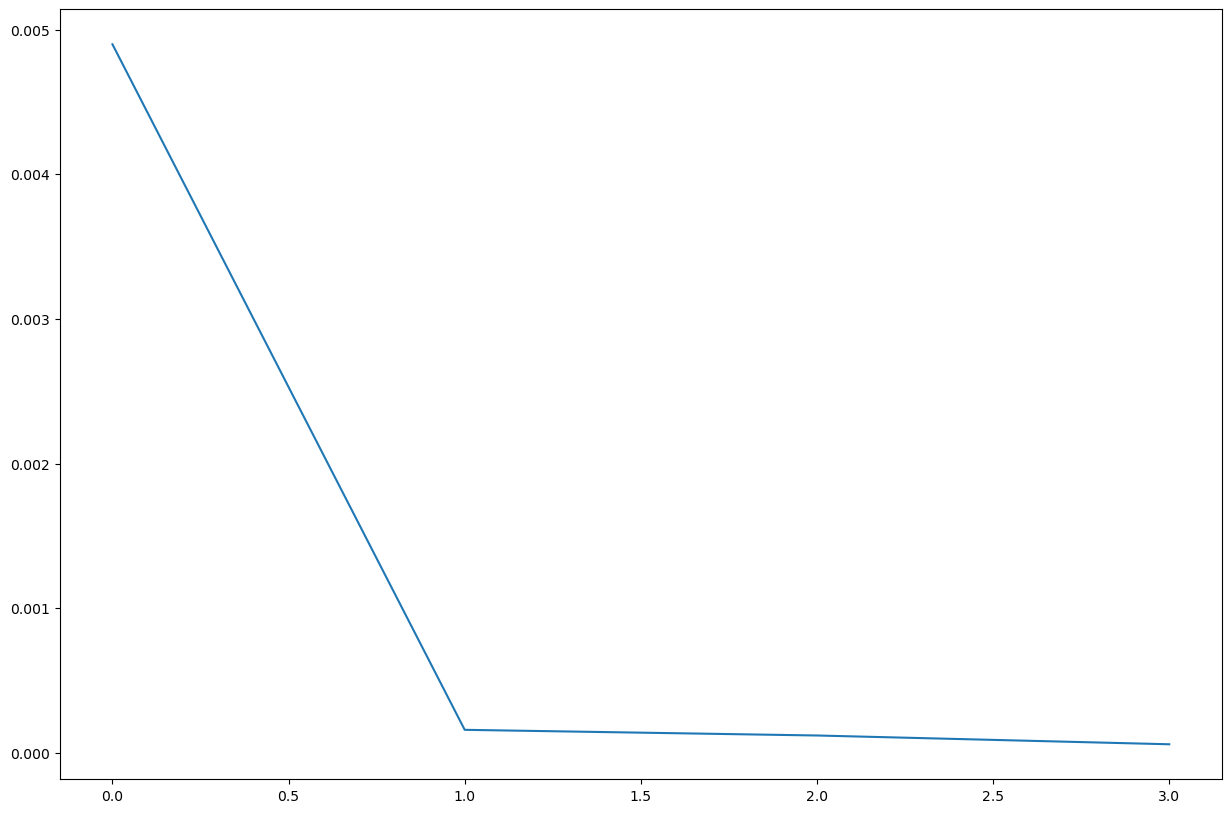

In [115]:
plt.plot(S[1:])

In [5]:
# Generated by Claude

In [6]:
import numpy as np
import pitts_py
from scipy.sparse.linalg import eigsh
from sklearn.cluster import KMeans

DATA = "/scratch/CERN_ATLAS_top_tagging/npy/"
M, c, n = 2**16, 700, 16384                        # chunk size, chunk index, subset size

def sub_tt(tt, c_first=None, c_last=None):
    """Fix the index of the first and/or last mode and return a smaller TT."""
    dims = list(tt.dimensions())
    cores = [np.asarray(tt.getSubTensor(k)) for k in range(len(dims))]   # (r_l, n, r_r)
    if c_first is not None:
        v = cores[0][:, c_first, :]
        r1, nn, r2 = cores[1].shape
        cores[1] = (v @ cores[1].reshape(r1, nn * r2)).reshape(1, nn, r2)
        cores = cores[1:]
    if c_last is not None:
        v = cores[-1][:, c_last, :]
        r0, nn, r1 = cores[-2].shape
        cores[-2] = (cores[-2].reshape(r0 * nn, r1) @ v).reshape(r0, nn, 1)
        cores = cores[:-1]
    new = pitts_py.TensorTrain_double(dimensions=[G.shape[1] for G in cores])
    new.setTTranks([G.shape[2] for G in cores[:-1]])
    for k, G in enumerate(cores):
        new.setSubTensor(k, G)
    return new

def kernel(X, sigma):
    """Dense Gaussian kernel exp(-|x_i - x_j|^2 / (2 sigma^2)), built in place."""
    nrm = np.einsum("ij,ij->i", X, X)
    K = X @ X.T
    K *= -2; K += nrm[:, None]; K += nrm[None, :]
    np.maximum(K, 0, out=K)
    K *= -1 / (2 * sigma**2); np.exp(K, out=K)
    return K

def spectral(K, y, k=8, neig=10):
    """Normalized spectral clustering (NJW); returns top eigenvalues and purity."""
    d = K.sum(1); h = 1 / np.sqrt(d)
    K *= h[:, None]; K *= h[None, :]
    th, V = eigsh(K, k=neig, which="LA")
    th, V = th[::-1], V[:, ::-1]
    Y = V[:, 1:k]; Y /= np.linalg.norm(Y, axis=1, keepdims=True)
    lab = KMeans(k, n_init=3, random_state=0).fit_predict(Y)
    pur = sum(max(y[lab == j].mean(), 1 - y[lab == j].mean()) * (lab == j).mean()
              for j in range(k) if (lab == j).any())
    return th, pur

# exact data and labels of chunk c
sl = slice(c * M, (c + 1) * M)
Xe = np.asarray(np.load(DATA + "const_unit_c_partially_ordered.npy", mmap_mode="r")[sl], np.float64)
yc = np.load(DATA + "labels_partially_ordered.npy")[sl]

# approximated data of chunk c (transposed TT: [1401, 2 x 16 (reversed), 1416])
print(list(Xtt.dimensions()), flush=True)
T = np.asarray(pitts_py.toDense(sub_tt(Xtt, c_last=c)))
Xa = (T.reshape([-1] + [2] * 16)
       .transpose([0] + list(range(16, 0, -1)))
       .reshape(-1, M).T)
del T

# 1. approximation error
print("rel. data error:", np.linalg.norm(Xa - Xe) / np.linalg.norm(Xe), flush=True)

# 2. bit-order check: mean |e_i|^2 ~ mean (1 - |x~_i|^2) for a correct projection
print("mean |e|^2:", np.mean(((Xa - Xe)**2).sum(1)),
      " mean 1-|x~|^2:", np.mean(1 - (Xa**2).sum(1)), flush=True)

# 3. best possible rank-r approximation in feature space (PCA of the chunk)
s = np.linalg.svd(Xe, compute_uv=False)
e = np.cumsum(s**2) / np.sum(s**2)
print("PCA energy top-100/500/1000:", e[99], e[499], e[999], flush=True)

# 4. spectral clustering on a random subset: exact vs approximated data
rng = np.random.default_rng(0)
idx = np.sort(rng.choice(M, n, replace=False))
Xe_s, Xa_s, y = Xe[idx], Xa[idx], yc[idx]
for sigma in [0.3, 0.5, 1.0]:
    for name, X in [("exact", Xe_s), ("approx", Xa_s)]:
        th, pur = spectral(kernel(X, sigma), y)
        print(f"sigma={sigma} {name}: theta[:6]={np.round(th[:6], 3)}, purity={pur:.3f}",
              flush=True)

[1401, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1416]
rel. data error: 0.46209942250966796
mean |e|^2: 0.21353588208596275  mean 1-|x~|^2: 0.21354623612609264
PCA energy top-100/500/1000: 0.9089575994096152 0.9963316560470191 0.999997586509432
sigma=0.3 exact: theta[:6]=[1.    0.22  0.131 0.082 0.073 0.062], purity=0.632
sigma=0.3 approx: theta[:6]=[1.    0.056 0.007 0.002 0.001 0.   ], purity=0.638
sigma=0.5 exact: theta[:6]=[1.    0.086 0.048 0.033 0.022 0.015], purity=0.649
sigma=0.5 approx: theta[:6]=[1.    0.02  0.002 0.001 0.    0.   ], purity=0.638
sigma=1.0 exact: theta[:6]=[1.    0.023 0.012 0.009 0.006 0.004], purity=0.641
sigma=1.0 approx: theta[:6]=[1.    0.005 0.001 0.    0.    0.   ], purity=0.638


In [ ]:
# Another Claude test

In [12]:
import numpy as np
import pitts_py

DATA = "/scratch/CERN_ATLAS_top_tagging/npy/"
B, D, start = 18, 1401, 0                          # 2^18 jets, features, block offset
n = 2**B
X  = np.asarray(np.load(DATA + "const_unit_c.npy", mmap_mode="r")[start:start + n], np.float32)
hl = np.load(DATA + "hl.npy", mmap_mode="r")
pt, m = np.asarray(hl[start:start + n, 15]), np.asarray(hl[start:start + n, 16])

def rank(v):                                       # quantile rank 0..n-1
    r = np.empty(len(v), dtype=np.uint64)
    r[np.argsort(v, kind="stable")] = np.arange(len(v), dtype=np.uint64)
    return r

def morton2(a, b, bits):                           # interleave, a = more significant
    key = np.zeros(len(a), dtype=np.uint64)
    for k in range(bits):
        key |= ((a >> np.uint64(k)) & np.uint64(1)) << np.uint64(2 * k + 1)
        key |= ((b >> np.uint64(k)) & np.uint64(1)) << np.uint64(2 * k)
    return key

h = B // 2
keys = {
    "random": np.arange(n, dtype=np.uint64),
    "pT":     rank(pt),
    "pT+m":   morton2(rank(pt) >> np.uint64(B - h), rank(m) >> np.uint64(B - h), h),
}

s = np.linalg.svd(X.astype(np.float64), compute_uv=False)
e = np.cumsum(s**2) / np.sum(s**2)
print("PCA energy top-100/500/1000:", e[99], e[499], e[999], flush=True)

dims = [D] + [2] * (B-10) + [2**10]                               # features, then bits of p (LSB first)
for name, key in keys.items():
    Xs = np.ascontiguousarray(X[np.argsort(key, kind="stable")])   # C order, row p = sorted pos.
    A = np.reshape(Xs.ravel(), (Xs.size // dims[-1], dims[-1]), order="F")       # view, no copy

    mv = pitts_py.MultiVector_float(A.shape[0], A.shape[1])
    np.asarray(mv)[...] = A                        # copy into (padded) MultiVector

    work = pitts_py.MultiVector_float()
    tt = pitts_py.fromDense_twoSided(mv, work, dims, rankTolerance=1e-2, maxRank=1000)
    T = np.asarray(pitts_py.toDense(tt))           # dims [D, 2 x B]
    Xa = np.reshape(T, (D, n), order="F").T        # back to (n, D), row p
    err = np.linalg.norm(Xa - Xs) / np.linalg.norm(Xs)
    print(f"{name}: ranks={tt.getTTranks()}, rel. error={err:.3f}", flush=True)

PCA energy top-100/500/1000: 0.9080307804428528 0.9961643900360592 0.9999951623339767
TT-SVD::split  matrix dimensions: 358656 x 1024
n: 1024, rank: 1024, maxRank: 1000, rankTol: 0.00333333, initialFrobeniusNorm: 511.999
singular values:  0.883136 0.0202292 0.0201311 0.0200938 0.0200257 0.0200086 0.0198716 0.0197899 0.0197539 0.0197401 0.0197259 0.0196628 0.0196462 0.0196027 0.0195951 0.0195423 0.0195218 0.0195014 0.0194526 0.0194113 0.0193959 0.0193592 0.0193015 0.0192771 0.0192606 0.0192396 0.0192143 0.0191701 0.0191455 0.0191134 0.0190858 0.0190724  0.019021 0.0189984 0.0189689 0.0189546 0.0189471 0.0189054 0.0188972 0.0188632 0.0188416 0.0188081 0.0187942 0.0187398 0.0187261 0.0186943 0.0186597 0.0186515 0.0186376 0.0186184 0.0185659 0.0185458  0.018527 0.0185076 0.0184897 0.0184606 0.0184533 0.0184049 0.0183989 0.0183811 0.0183767 0.0183334 0.0183222 0.0182974 0.0182889 0.0182629 0.0182497 0.0182273 0.0181877 0.0181708 0.0181567 0.0181413 0.0181111 0.0181081 0.0180948 0.0180631  0

In [ ]:
# PCA QTT ordering by Claude

In [15]:
import numpy as np
import pitts_py

DATA = "/scratch/CERN_ATLAS_top_tagging/npy/"
B, D, start, p = 18, 1401, 0, 8                    # 2^18 jets, features, offset, #PCs
n = 2**B
X = np.asarray(np.load(DATA + "const_unit_c.npy", mmap_mode="r")[start:start + n], np.float32)

# PCA (covariance eigendecomposition, float64)
mu = X.mean(0, dtype=np.float64)
Xc = X - mu.astype(np.float32)
w, V = np.linalg.eigh(Xc.T.astype(np.float64) @ Xc)
w, V = w[::-1], V[:, ::-1]
print("PCA energy (centered) top-4/8/100/500:",
      *(w[:k].sum() / w.sum() for k in (4, 8, 100, 500)), flush=True)
P = Xc @ V[:, :p].astype(np.float32)               # (n, p) PC scores

def kd_order(P, levels):
    """Balanced k-d tree in PC space: per block split at the median of the
    PC with the largest variance in that block. Returns order (position -> jet)."""
    order = np.arange(len(P))
    nb = 1
    for _ in range(levels):
        bs = len(P) // nb
        Pb = P[order].reshape(nb, bs, -1)
        ax = Pb.var(1).argmax(1)                                   # (nb,)
        key = np.take_along_axis(Pb, ax[:, None, None], 2)[..., 0] # (nb, bs)
        o = np.argsort(key, axis=1, kind="stable")
        order = np.take_along_axis(order.reshape(nb, bs), o, 1).ravel()
        nb *= 2
    return order

def leaf_explained(Y, order, level):
    """Fraction of variance explained by block means at a tree level (upper bound
    for what the sample modes can capture there)."""
    Yb = (Y[order] - Y.mean(0)).reshape(2**level, -1, Y.shape[1])
    return (Yb.mean(1, keepdims=True)**2).sum() * Yb.shape[1] / (Yb**2).sum()

def tt_test(Y, name):
    """TT-SVD of Y (rows already in QTT order), report ranks and error."""
    d = Y.shape[1]
    dims = [d] + [2] * (B-10) + [2**10]
    Ys = np.ascontiguousarray(Y, dtype=np.float32)
    A = np.reshape(Ys.ravel(), (Ys.size // dims[-1], dims[-1]), order="F")        # dims [d] + [2]*B
    mv = pitts_py.MultiVector_float(A.shape[0], A.shape[1])
    np.asarray(mv)[...] = A
    work = pitts_py.MultiVector_float()
    tt = pitts_py.fromDense_twoSided(mv, work, dims, rankTolerance=1e-2, maxRank=1000)
    Ya = np.reshape(np.asarray(pitts_py.toDense(tt)), (d, n), order="F").T
    err = np.linalg.norm(Ya - Ys) / np.linalg.norm(Ys)
    print(f"{name}: ranks={tt.getTTranks()}, rel. error={err:.3f}", flush=True)

orders = {"random": np.arange(n), "PCA k-d": kd_order(P, B)}
for name, o in orders.items():
    print(name, "explained by block means at level 6/10/14:",
          *(round(leaf_explained(X, o, L), 3) for L in (6, 10, 14)), flush=True)

# sanity check: the PC scores themselves must compress well with the k-d order
for name, o in orders.items():
    tt_test(P[o], f"PC scores, {name}")

# actual test
for name, o in orders.items():
    tt_test(X[o], f"X, {name}")

PCA energy (centered) top-4/8/100/500: 0.22697231293097697 0.2849533886556067 0.5836548453857672 0.9825921388670725
random explained by block means at level 6/10/14: 0.0 0.004 0.063
PCA k-d explained by block means at level 6/10/14: 0.236 0.287 0.355
TT-SVD::split  matrix dimensions: 2048 x 1024
n: 1024, rank: 1024, maxRank: 1000, rankTol: 0.00333333, initialFrobeniusNorm: 128.285
singular values:  0.0634159  0.0629287   0.062687   0.062468    0.06215  0.0616961  0.0613063  0.0611109  0.0609349  0.0607364   0.060536  0.0604177  0.0601652  0.0599938  0.0598751  0.0597966  0.0597488  0.0593196  0.0591579  0.0589421  0.0588474  0.0587645  0.0584565  0.0584064  0.0583877  0.0580867  0.0579808  0.0577225  0.0576723  0.0573735  0.0572978  0.0571475  0.0570394  0.0568331  0.0567297  0.0566051  0.0565945   0.056514  0.0563097  0.0560638  0.0559669  0.0558632  0.0558305  0.0556609  0.0553696  0.0552899  0.0551752  0.0551184  0.0550112  0.0546508  0.0545675   0.054501  0.0544725  0.0541899  0.05

In [9]:
# OLD stuff below
n_samples = 1416*2**16
weights = np.load('/scratch/CERN_ATLAS_top_tagging/npy/weights.npy')[:n_samples]

In [15]:
def contractWeights(Xtt, weights):
    dims = Xtt.dimensions()
    tmp = weights
    for i in range(len(dims)//2):
        subT = Xtt.getSubTensor(i)
        nr = subT.shape[0]*subT.shape[1]
        tmp = tmp.reshape((nr, tmp.size//nr), order='F')
        tmp = subT.reshape((nr, subT.shape[2]), order='F').T @ tmp
    return tmp

In [16]:
def contractWeightsReverse(Xtt, d):
    dims = Xtt.dimensions()
    tmp = d
    for i in reversed(range(len(dims)//2)):
        subT = Xtt.getSubTensor(i)
        r = subT.shape[2]
        print(i, 'shape', subT.shape, 'tmp.shape', tmp.shape)
        tmp = tmp.reshape((r, tmp.size//r), order='F')
        tmp = subT.reshape((subT.size//r, r), order='F') @ tmp
    return tmp.reshape((tmp.size,), order='F')

In [17]:
%%time
d = contractWeights(Xtt_Gaussian, weights)
d = np.diag(S) @ d
d = contractWeightsReverse(Xtt_Gaussian, d)
g = weights / d

16 shape (184, 2, 115) tmp.shape (115, 1)
15 shape (313, 2, 184) tmp.shape (368, 1)
14 shape (509, 2, 313) tmp.shape (626, 2)
13 shape (549, 2, 509) tmp.shape (1018, 4)
12 shape (549, 2, 549) tmp.shape (1098, 8)
11 shape (550, 2, 549) tmp.shape (1098, 16)
10 shape (550, 2, 550) tmp.shape (1100, 32)
9 shape (550, 2, 550) tmp.shape (1100, 64)
8 shape (550, 2, 550) tmp.shape (1100, 128)
7 shape (550, 2, 550) tmp.shape (1100, 256)
6 shape (550, 2, 550) tmp.shape (1100, 512)
5 shape (550, 2, 550) tmp.shape (1100, 1024)
4 shape (550, 2, 550) tmp.shape (1100, 2048)
3 shape (550, 2, 550) tmp.shape (1100, 4096)
2 shape (550, 2, 550) tmp.shape (1100, 8192)
1 shape (550, 2, 550) tmp.shape (1100, 16384)
0 shape (1, 1416, 550) tmp.shape (1100, 32768)
CPU times: user 2min 23s, sys: 8.91 s, total: 2min 32s
Wall time: 6.54 s


In [18]:
ei = np.zeros(weights.size, dtype=np.float32)
ei[0] = 1
d = contractWeights(Xtt_Gaussian, ei)
d.T @ np.diag(S) @ d

array([[0.92233167]])

In [19]:
ei = pitts_py.TensorTrain_double(Xtt_Gaussian.dimensions())
ei.setUnit([0,]*len(ei.dimensions()))
pitts_py.dot(Xtt_Gaussian, ei)

0.7763485184227912

In [20]:
dims = Xtt_Gaussian.dimensions()
tmp_tt = pitts_py.TensorTrain_double(dims)
tmp_tt.setTTranks(list(reversed(Xtt_Gaussian.getTTranks())))
for i in range(len(dims)):
    tmp_tt.setSubTensor(i, Xtt_Gaussian.getSubTensor(len(dims)-i-1).T)
#pitts_py.normalize(tmp_tt)
pitts_py.axpby(1, Xtt_Gaussian, -1, tmp_tt) / pitts_py.norm2(Xtt_Gaussian)

0.08166918117599253

In [21]:
#nrm_Gaussian = pitts_py.normalize(Xtt_Gaussian)
#print(nrm_Gaussian)

In [22]:
#dims = Xtt_Gaussian.dimensions()
#g_mv = pitts_py.MultiVector_double(g.size//2, 2)
#g_view = np.array(g_mv, copy=False)
#g_view[:,:] = g.reshape((g.size//2, 2), order='F')
#work = pitts_py.MultiVector_double(g.size//2, 2)
#g_tt = pitts_py.fromDense_twoSided(g_mv, work, dims[:len(dims)//2], maxRank=500, rankTolerance=0.001)
#print(g_tt)

In [23]:
#dims = Xtt_Gaussian.dimensions()
#w_mv = pitts_py.MultiVector_double(weights.size//2, 2)
#w_view = np.array(w_mv, copy=False)
#w_view[:,:] = weights.reshape((weights.size//2, 2), order='F')
#work = pitts_py.MultiVector_double(weights.size//2, 2)
#w_tt = pitts_py.fromDense_twoSided(w_mv, work, dims[:len(dims)//2], maxRank=500, rankTolerance=0.001)
#print(w_tt)

In [10]:
hl = np.load("/scratch/CERN_ATLAS_top_tagging/npy/hl.npy", mmap_mode="r")[:n_samples,:]
pt = np.asarray(hl[:, 15])
order = np.argsort(pt, kind="stable")

In [11]:
mass = np.asarray(hl[:, 16])

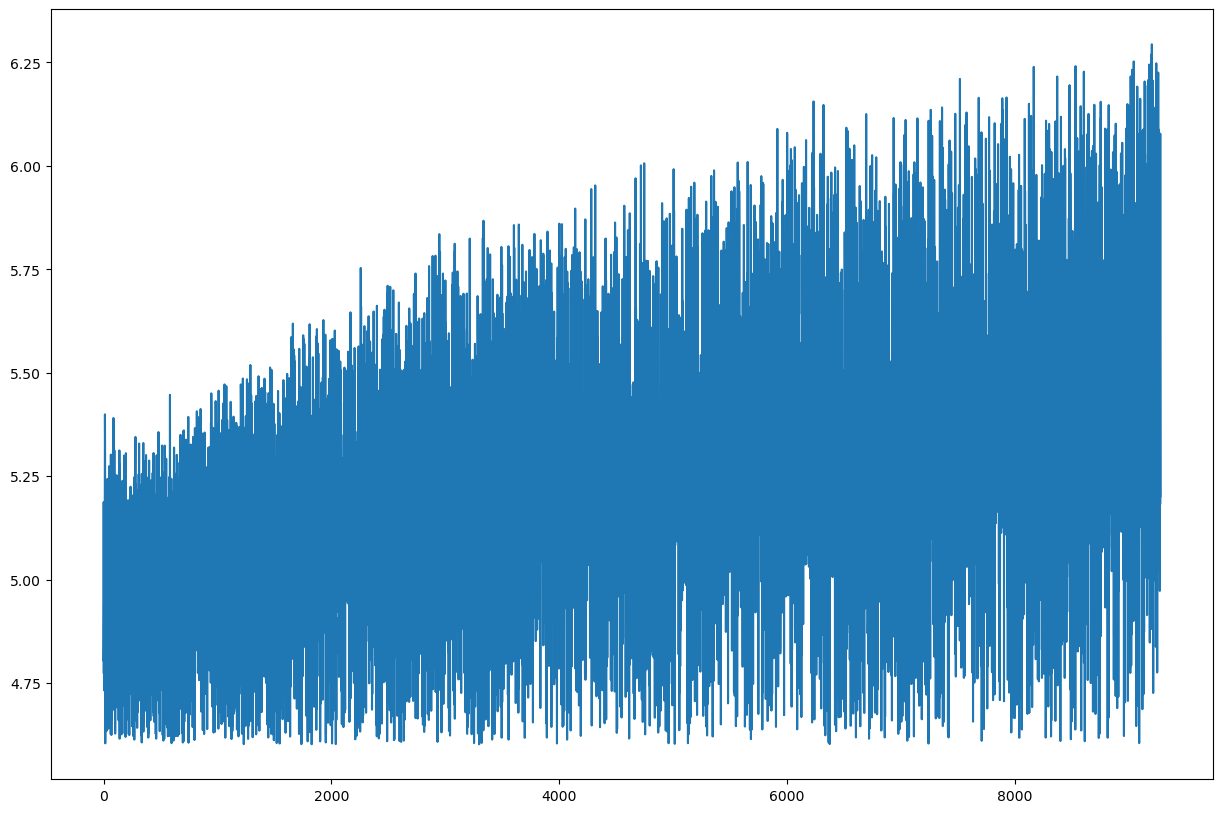

In [19]:
plt.plot(np.log10(mass[order[::10000]]))